## Import Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

from sklearn.base import clone

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


## Load Dataset

In [ ]:
credit = fetch_openml(
    data_id=31,
    as_frame=True,
    parser="auto"
)

df = credit.frame.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [ ]:
print("Dataset Information:")
print(df.info())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df["class"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  hous

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad



Dataset columns:
['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'personal_status', 'other_parties', 'residence_since', 'property_magnitude', 'age', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker', 'class']

Missing values:
0

Target distribution:
class
good    700
bad     300
Name: count, dtype: int64


## Prepare the Target Variable

Target mapping completed!

0 = Good Credit
1 = Bad Credit

Target distribution:
target
0    700
1    300
Name: count, dtype: int64


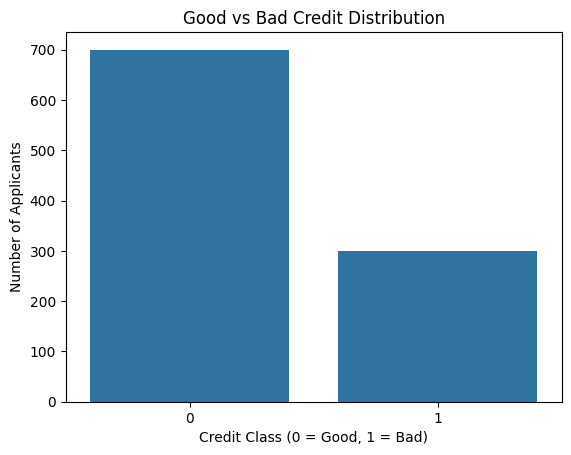

In [ ]:
# Convert target labels to strings
df["class"] = df["class"].astype(str).str.strip()

# Convert target to binary values
df["target"] = df["class"].map({
    "1": 0,
    "2": 1,
    "good": 0,
    "bad": 1
})

# Check whether target conversion was successful
if df["target"].isnull().any():
    raise ValueError(
        f"Unexpected target labels: {df['class'].unique()}"
    )

# Remove original target column
df.drop(columns=["class"], inplace=True)

print("Target mapping completed!")
print("\n0 = Good Credit")
print("1 = Bad Credit")

print("\nTarget distribution:")
print(df["target"].value_counts())

sns.countplot(data=df, x="target")
plt.title("Good vs Bad Credit Distribution")
plt.xlabel("Credit Class (0 = Good, 1 = Bad)")
plt.ylabel("Number of Applicants")
plt.show()

In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
checking_status,1000,4,no checking,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
credit_history,1000,5,existing paid,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purpose,1000,10,radio/tv,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
savings_status,1000,5,<100,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment,1000,5,1<=X<4,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
installment_commitment,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
personal_status,1000,4,male single,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
other_parties,1000,3,none,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN


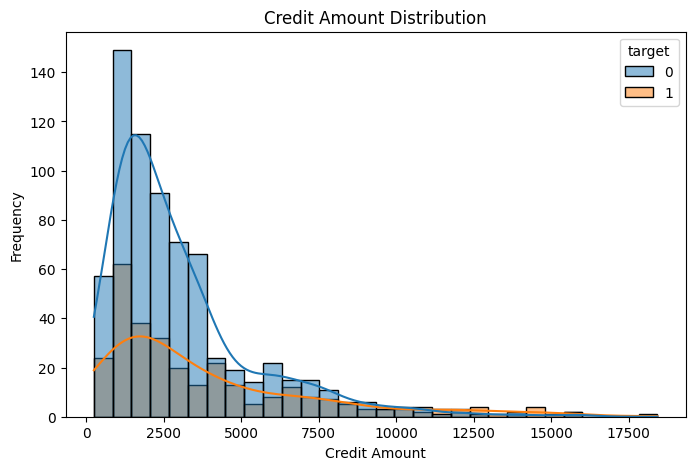

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="credit_amount",
    hue="target",
    bins=30,
    kde=True
)

plt.title("Credit Amount Distribution")
plt.xlabel("Credit Amount")
plt.ylabel("Frequency")
plt.show()

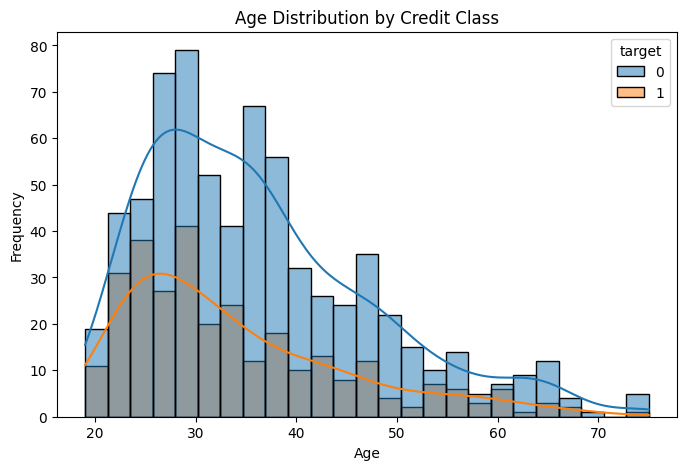

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue="target",
    bins=25,
    kde=True
)

plt.title("Age Distribution by Credit Class")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

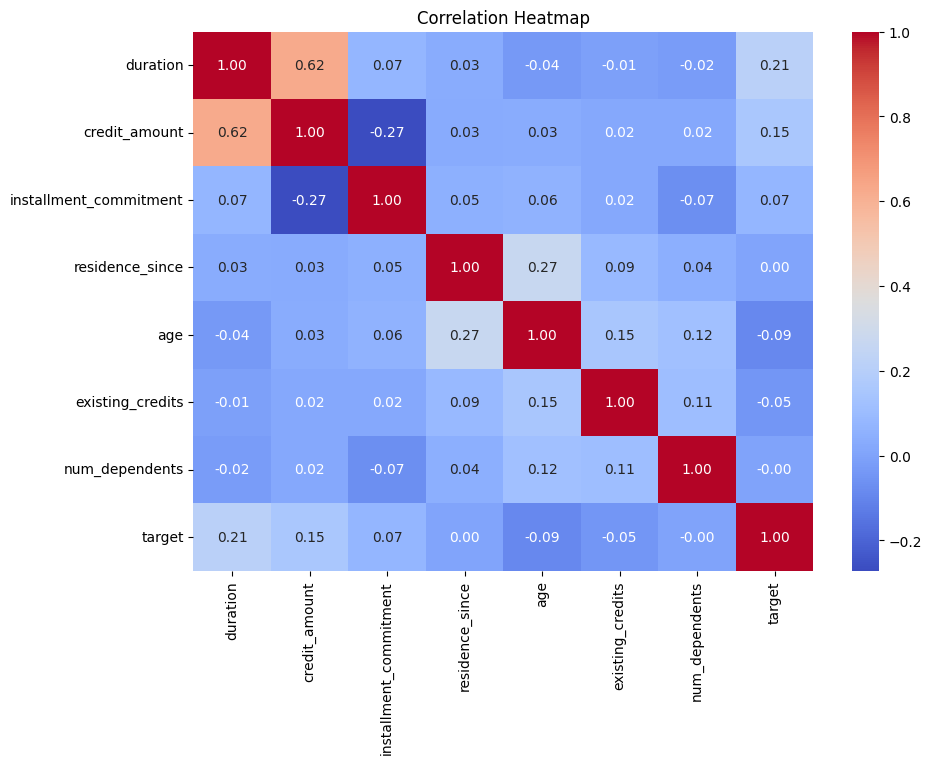

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## Feature Engineering

In [ ]:
# Credit amount relative to loan duration
df["credit_amount_per_month"] = (
    df["credit_amount"] /
    df["duration"].replace(0, np.nan)
)

# Age categories
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 50, 100],
    labels=[
        "Young",
        "Early_Middle",
        "Middle_Aged",
        "Older"
    ],
    include_lowest=True
)

# Credit duration categories
df["credit_duration_group"] = pd.cut(
    df["duration"],
    bins=[0, 12, 24, 48, np.inf],
    labels=[
        "Short",
        "Medium",
        "Long",
        "Very_Long"
    ],
    include_lowest=True
)

print("Feature engineering completed!")

display(df.head())

Feature engineering completed!


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,target,credit_amount_per_month,age_group,credit_duration_group
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,own,2,skilled,1,yes,yes,0,194.833333,Older,Short
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,own,1,skilled,1,none,yes,1,123.979167,Young,Long
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,own,1,unskilled resident,2,none,yes,0,174.666667,Middle_Aged,Short
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,for free,1,skilled,2,none,yes,0,187.666667,Middle_Aged,Long
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,for free,2,skilled,2,none,yes,1,202.916667,Older,Medium


## Seperate Features and Target

In [ ]:
X = df.drop(columns=["target"])
y = df["target"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Feature matrix shape: (1000, 23)
Target shape: (1000,)

Target classes:
target
0    700
1    300
Name: count, dtype: int64


## Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 800
Testing samples: 200

Training target distribution:
target
0    0.7
1    0.3
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.7
1    0.3
Name: proportion, dtype: float64


## Preprocessing Pipeline

In [ ]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents', 'credit_amount_per_month']

Categorical features: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker', 'age_group', 'credit_duration_group']


### Preprocessing Transformers

In [ ]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


## Define Machine Learning Models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Models defined successfully!")

Models defined successfully!


## Train All Models

In [ ]:
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("classifier", clone(model))
        ]
    )

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} training completed!")

print("\nAll models trained successfully!")


Training Logistic Regression...
Logistic Regression training completed!

Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!

All models trained successfully!


## Evaluate All Models

In [ ]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test, y_pred
        ),

        "Precision": precision_score(
            y_test, y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, y_pred,
            zero_division=0
        ),

        "F1-Score": f1_score(
            y_test, y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test, y_prob
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7650,0.6066,0.6167,0.6116,0.8010
1,Logistic Regression,0.7200,0.5222,0.7833,0.6267,0.7990
2,Decision Tree,0.5850,0.3814,0.6167,0.4713,0.6260


## Visualize Model Performance

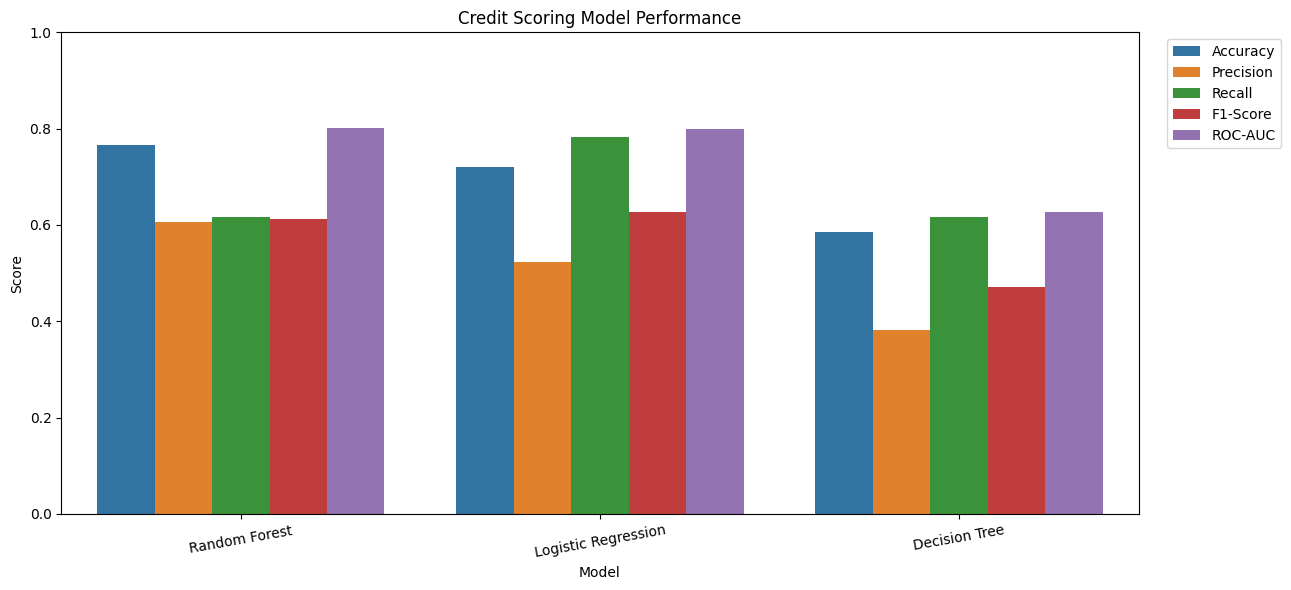

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Credit Scoring Model Performance")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Confusion Matrix

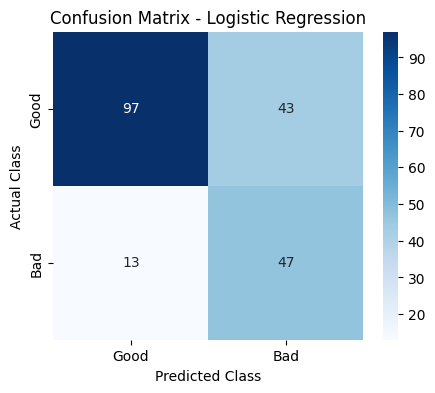

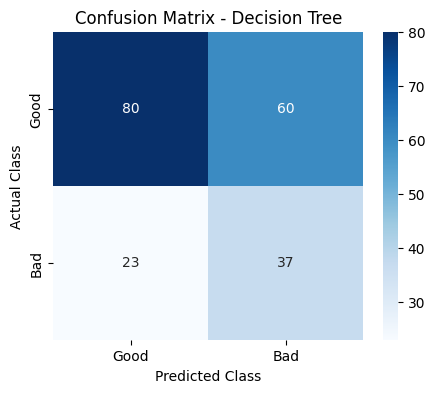

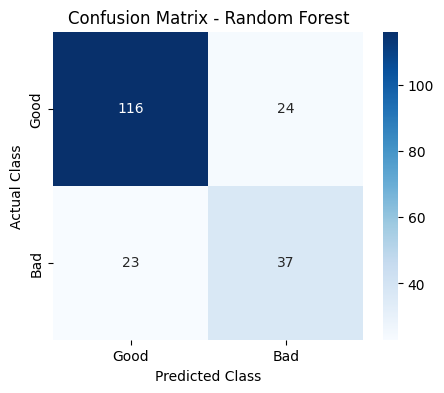

In [ ]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Good", "Bad"],
        yticklabels=["Good", "Bad"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.show()

## Classification Report

In [ ]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=[
                "Good Credit",
                "Bad Credit"
            ],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

 Good Credit       0.88      0.69      0.78       140
  Bad Credit       0.52      0.78      0.63        60

    accuracy                           0.72       200
   macro avg       0.70      0.74      0.70       200
weighted avg       0.77      0.72      0.73       200


Decision Tree
              precision    recall  f1-score   support

 Good Credit       0.78      0.57      0.66       140
  Bad Credit       0.38      0.62      0.47        60

    accuracy                           0.58       200
   macro avg       0.58      0.59      0.56       200
weighted avg       0.66      0.58      0.60       200


Random Forest
              precision    recall  f1-score   support

 Good Credit       0.83      0.83      0.83       140
  Bad Credit       0.61      0.62      0.61        60

    accuracy                           0.77       200
   macro avg       0.72      0.72      0.72       200
weighted avg       0.77

## ROC Curve Comparison

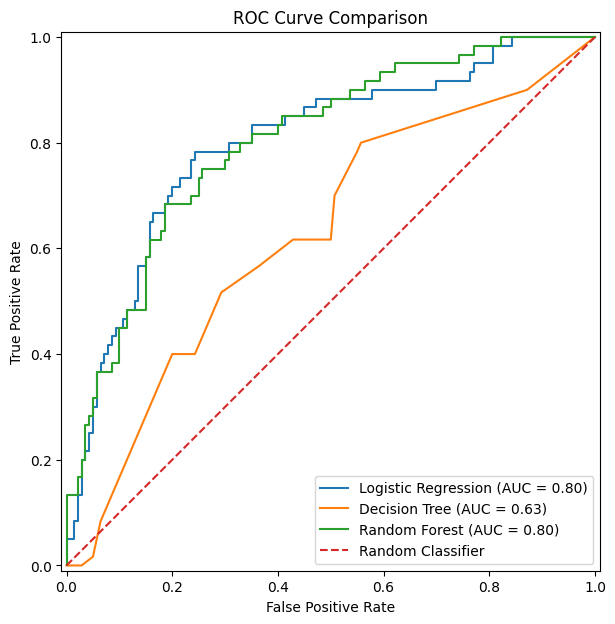

In [ ]:
plt.figure(figsize=(9, 7))

ax = plt.gca()

for name, model in trained_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## Hyperparameter Tuning

In [ ]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

param_grid = {
    "classifier__n_estimators": [
        100, 200, 300
    ],

    "classifier__max_depth": [
        5, 10, 15, None
    ],

    "classifier__min_samples_split": [
        2, 5, 10
    ],

    "classifier__min_samples_leaf": [
        1, 3, 5
    ]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 108 candidates, totalling 540 fits

Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 300}

Best Cross-Validation ROC-AUC:
0.7994


## Evaluate the Tuned Model

In [ ]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)

y_prob_best = best_model.predict_proba(X_test)[:, 1]

print("Tuned Random Forest Performance")
print("-" * 40)

print(
    "Accuracy:",
    round(
        accuracy_score(y_test, y_pred_best),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_test, y_pred_best,
            zero_division=0
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_test, y_pred_best,
            zero_division=0
        ),
        4
    )
)

print(
    "F1-Score:",
    round(
        f1_score(
            y_test, y_pred_best,
            zero_division=0
        ),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(y_test, y_prob_best),
        4
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=[
            "Good Credit",
            "Bad Credit"
        ],
        zero_division=0
    )
)

Tuned Random Forest Performance
----------------------------------------
Accuracy: 0.765
Precision: 0.6032
Recall: 0.6333
F1-Score: 0.6179
ROC-AUC: 0.7945

Classification Report:

              precision    recall  f1-score   support

 Good Credit       0.84      0.82      0.83       140
  Bad Credit       0.60      0.63      0.62        60

    accuracy                           0.77       200
   macro avg       0.72      0.73      0.72       200
weighted avg       0.77      0.77      0.77       200



## Feature Importance

Top 20 Important Features:


,Feature,Importance
11,cat__checking_status_no checking,0.089455
7,num__credit_amount_per_month,0.074595
1,num__credit_amount,0.072057
0,num__duration,0.068365
4,num__age,0.052438
9,cat__checking_status_<0,0.044397
13,cat__credit_history_critical/other existing cr...,0.030020
29,cat__savings_status_<100,0.026506
2,num__installment_commitment,0.023207
8,cat__checking_status_0<=X<200,0.021333


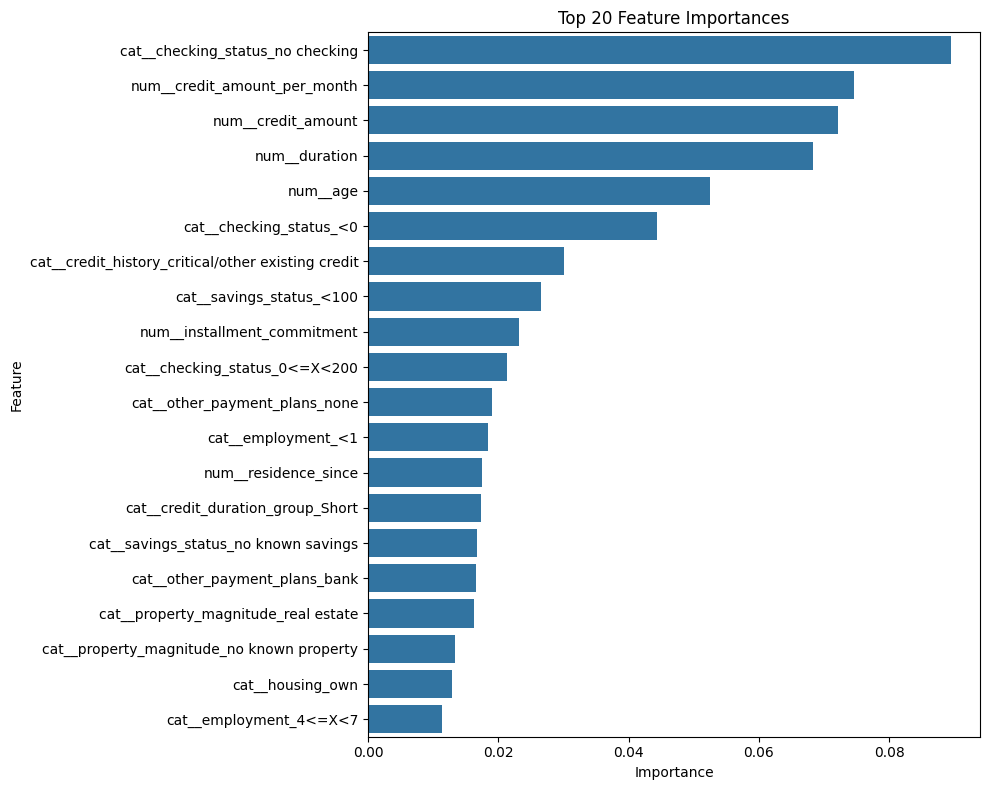

In [ ]:
# Get the fitted preprocessing component
fitted_preprocessor = best_model.named_steps[
    "preprocessor"
]

# Get transformed feature names
feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

# Extract Random Forest importance
importances = (
    best_model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features:")

display(importance_df.head(20))

# Plot top 20 features
top_features = importance_df.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Feature Importances")
plt.tight_layout()
plt.show()

## Predict a New Applicant

In [ ]:
# Select one applicant from the test set
sample_applicant = X_test.iloc[[0]].copy()

print("Applicant Information:")
display(sample_applicant)

# Predict credit class
prediction = best_model.predict(
    sample_applicant
)[0]

# Predict probability of bad credit
bad_credit_probability = (
    best_model.predict_proba(
        sample_applicant
    )[0][1]
)

if prediction == 1:
    predicted_class = "Bad Credit"
else:
    predicted_class = "Good Credit"

print("\nPrediction Result")
print("-" * 40)

print("Predicted Class:", predicted_class)

print(
    "Estimated Bad Credit Probability:",
    f"{bad_credit_probability:.2%}"
)

Applicant Information:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,credit_amount_per_month,age_group,credit_duration_group
30,0<=X<200,18,existing paid,business,1913,>=1000,<1,3,male mar/wid,none,...,bank,own,1,skilled,1,yes,yes,106.277778,Middle_Aged,Medium



Prediction Result
----------------------------------------
Predicted Class: Good Credit
Estimated Bad Credit Probability: 38.54%


## Create a Reusable Prediction Function

In [ ]:
def predict_creditworthiness(applicant_data, model):

    # Convert dictionary into DataFrame
    applicant_df = pd.DataFrame(
        [applicant_data]
    )

    # Ensure the input columns match training data
    applicant_df = applicant_df.reindex(
        columns=X_train.columns
    )

    # Predict class and probability
    prediction = model.predict(
        applicant_df
    )[0]

    probability = model.predict_proba(
        applicant_df
    )[0][1]

    result = {
        "Predicted Class": (
            "Bad Credit"
            if prediction == 1
            else "Good Credit"
        ),

        "Bad Credit Probability": round(
            float(probability), 4
        )
    }

    return result

## Save the Trained Model

In [ ]:
import joblib

joblib.dump(
    best_model,
    "credit_scoring_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download(
    "credit_scoring_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Project Summary

In [ ]:
print("=" * 60)
print("CREDIT SCORING MODEL - PROJECT SUMMARY")
print("=" * 60)

print("Dataset: German Credit Risk")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nModels Evaluated:")
for name in trained_models.keys():
    print("-", name)

print("\nTuned Model: Random Forest")

print(
    "Best CV ROC-AUC:",
    round(grid_search.best_score_, 4)
)

print(
    "Test ROC-AUC:",
    round(
        roc_auc_score(y_test, y_prob_best),
        4
    )
)

print("\nProject completed successfully!")

CREDIT SCORING MODEL - PROJECT SUMMARY
Dataset: German Credit Risk
Training Samples: 800
Testing Samples: 200

Models Evaluated:
- Logistic Regression
- Decision Tree
- Random Forest

Tuned Model: Random Forest
Best CV ROC-AUC: 0.7994
Test ROC-AUC: 0.7945

Project completed successfully!
